# 005 - Análisis exploratorio de datos (EDA)
---

* Ayuda a comprender la estructura, los patrones y la información de un conjunto de datos antes de comenzar a modelar
* Las principales herramientas que se utilizan para el EDA son **Matplotlib** y **Seaborn**, dos potentes bibliotecas de Python para visualizar datos
* Implica una combinación de herramientas estadísticas, técnicas de visualización y, en ocasiones, un poco de intuición para descubrir la estructura de un conjunto de datos
* El objetivo es comprender la composición de los datos, detectar valores atípicos o patrones inusuales y realizar observaciones iniciales que guiarán el análisis posterior
* Es un paso esencial que conduce a una mejor limpieza de datos, selección de características y diseño de modelos

## Pasos claves en EDA

1. **Resumen de datos**: analizar las estadísticas y estructuras básicas. Esto incluye comprender la forma de los datos (filas y columnas), estadísticas de resumen como la media, la mediana, el mínimo y el máximo, y la distribución de cada variable
1. **Limpieza de datos**: identificar cualquier valor faltante, duplicado o valor atípico que pueda sesgar los resultados
1. **Análisis univariado**: examinar una variable a la vez para comprender su distribución y características clave (por ejemplo, asimetría, modalidad)
1. **Análisis bivariado/multivariado**: analiza las relaciones entre dos o más variables, lo que puede revelar dependencias y correlaciones
1. **Visualización**: utilizar gráficos para que la información obtenida de los datos sea más accesible y visualmente atractiva

## 1. Carga e inspección de los datos

In [2]:
import pandas as pd

# Load data
df = pd.read_csv("data/employee_satisfaction.csv")

# Overview of data structure
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   employee_id          200 non-null    int64  
 1   age                  200 non-null    int64  
 2   years_at_company     200 non-null    int64  
 3   job_role             200 non-null    object 
 4   department           200 non-null    object 
 5   satisfaction_rating  200 non-null    float64
 6   monthly_income       200 non-null    int64  
dtypes: float64(1), int64(4), object(2)
memory usage: 11.1+ KB


,employee_id,age,years_at_company,satisfaction_rating,monthly_income
count,200.000000,200.00000,200.000000,200.000000,200.000000
mean,100.500000,40.17000,18.920000,3.008000,76223.800000
std,57.879185,11.24202,10.698875,1.138206,25902.305146
min,1.000000,22.00000,0.000000,1.000000,30060.000000
25%,50.750000,30.00000,10.750000,2.000000,54134.500000
50%,100.500000,41.00000,21.000000,3.000000,77180.500000
75%,150.250000,49.00000,28.000000,4.000000,98394.250000
max,200.000000,59.00000,34.000000,5.000000,119599.000000


## 2. Análisis univariado

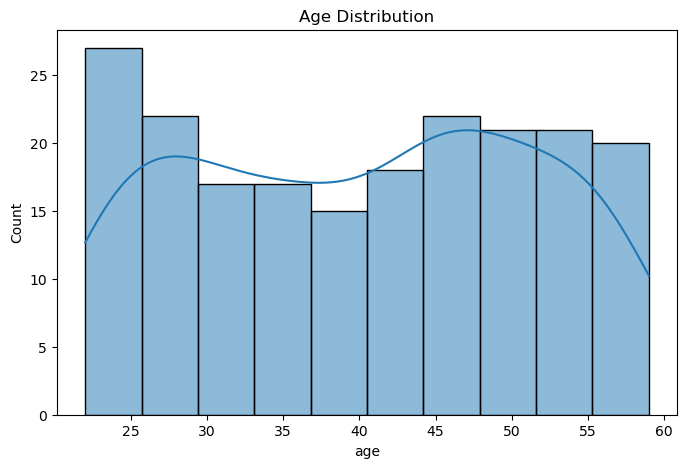

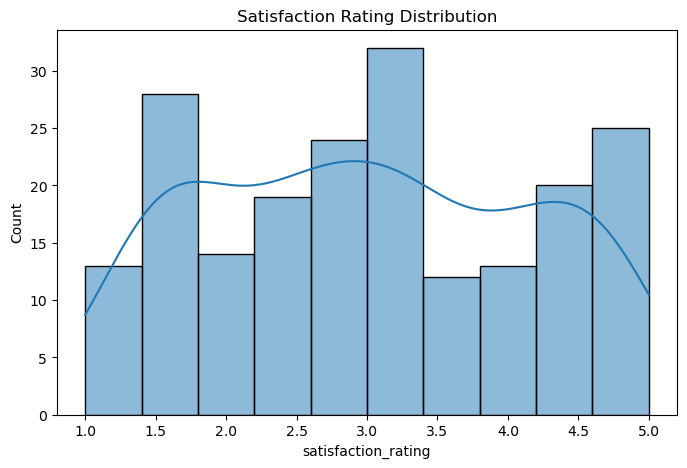

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot age distribution
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=10, kde=True)
plt.title("Age Distribution")
plt.show()

# Plot satisfaction ratings
plt.figure(figsize=(8, 5))
sns.histplot(df['satisfaction_rating'], bins=10, kde=True)
plt.title("Satisfaction Rating Distribution")
plt.show()

## 3. Análisis bivariado

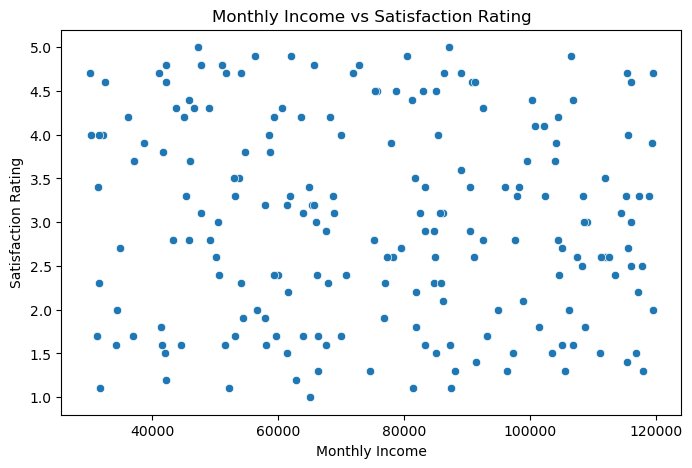

In [4]:
# Scatter plot for monthly income vs satisfaction rating
plt.figure(figsize=(8, 5))
sns.scatterplot(x='monthly_income', y='satisfaction_rating', data=df)
plt.title("Monthly Income vs Satisfaction Rating")
plt.xlabel("Monthly Income")
plt.ylabel("Satisfaction Rating")
plt.show()

## 4. Análisis de grupo

In [5]:
# Mean satisfaction by department
dept_satisfaction = df.groupby('department')['satisfaction_rating'].mean()
print("Average Satisfaction Rating by Department:\n", dept_satisfaction)

# Mean satisfaction by job role
role_satisfaction = df.groupby('job_role')['satisfaction_rating'].mean()
print("Average Satisfaction Rating by Job Role:\n", role_satisfaction)

Average Satisfaction Rating by Department:
 department
Finance       3.062963
HR            3.224444
IT            3.173913
Operations    2.711905
Sales         2.847500
Name: satisfaction_rating, dtype: float64
Average Satisfaction Rating by Job Role:
 job_role
Analyst       3.253125
Consultant    3.128000
Engineer      2.955000
Manager       2.762857
Technician    2.934884
Name: satisfaction_rating, dtype: float64


## 5. Análisis multivariado

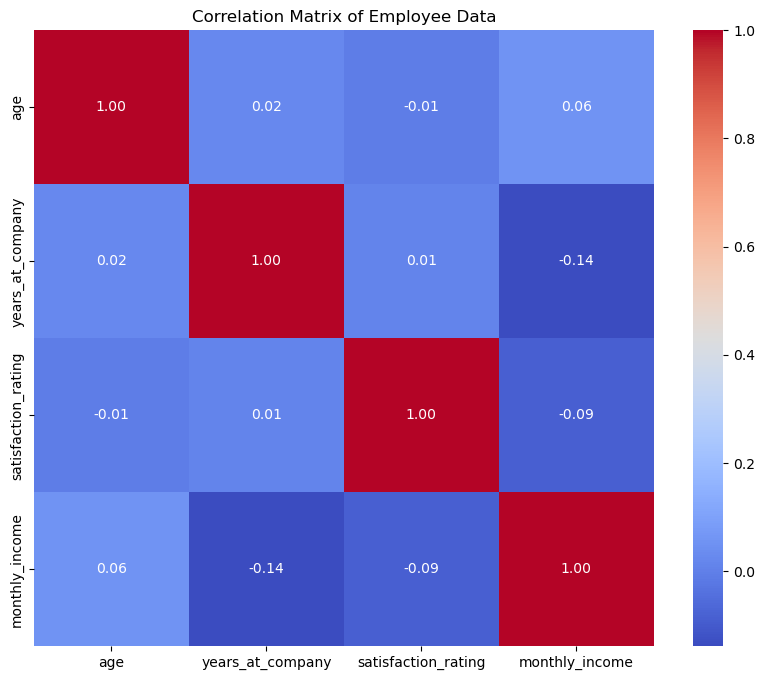

In [6]:
data = df[[ 'age', 'years_at_company','satisfaction_rating', 'monthly_income']]
plt.figure(figsize=(10, 8))
correlation_matrix = data.corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Employee Data")
plt.show()

## Conceptos y técnicas clave en EDA

* **Distribución**: muestra cómo se distribuyen los valores de una variable a lo largo de un rango
* **Valores atípicos**: valores inusualmente altos o bajos que pueden sesgar el análisis y podrían necesitar un tratamiento especial
* **Correlación**: medida estadística de cómo dos variables se relacionan entre sí; esencial para encontrar características con poder predictivo
* **Asimetría y curtosis**: indicadores de la forma de una distribución; útiles para comprender si los datos se distribuyen normalmente o tienen valores más extremos